# Make your own weather forecast map 🌡️
### ECMWF free & open data · 9 km · Greece, the week ahead, every island

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/greece_forecast.ipynb)

Everything here uses **free, open data** from ECMWF and open-source Python. In a few cells you'll
pull the latest **9 km** forecast, bin it into hexagons, and map the **afternoon temperature across
Greece**, from the mainland to the smallest islands, for each of the next seven days.

Then change one line and make it for **your** country, day, or variable.

*In Google Colab? Press **Runtime → Run all**. Nothing to install on your own computer.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q ecmwf-opendata earthkit-data cfgrib eccodes cartopy shapely h3

In [2]:
import datetime as dt, json, urllib.request
from zoneinfo import ZoneInfo
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.cm as mcm
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
from shapely.geometry import Polygon, shape
from shapely.prepared import prep
import h3
import earthkit.data as ekd
from ecmwf.opendata import Client

## 1 · Choose what to map

`DAY = 1` is tomorrow, `DAY = 0` today, up to `DAY = 6`. `HOUR` is the time of day in UTC
(12 UTC is 14:00 in Athens in winter, the warmest part of the day).
Change `COUNTRY`, `ISO3`, `CAPITAL` and `BBOX` to make the map for another country.

In [3]:
COUNTRY = "Greece"
ISO3    = "GRC"                                      # country code, picks the border file
CAPITAL = ("Athens", 37.984, 23.728)                 # name, lat, lon
CITIES  = [("Thessaloniki", 40.640, 22.944), ("Ioannina", 39.665, 20.854), ("Patras", 38.246, 21.735),
           ("Corfu", 39.624, 19.922), ("Mytilene", 39.110, 26.555), ("Rhodes", 36.434, 28.217),
           ("Heraklion", 35.339, 25.144)]
TIMEZONE = "Europe/Athens"
DAY     = 1                                          # 0 = today ... 6 = six days ahead
HOUR    = 12                                         # UTC
BBOX    = (19.0, 30.0, 34.6, 41.9)                   # W, E, S, N: Corfu to Kastellorizo, Gavdos to Evros
RES     = 5                                          # H3 hexagon size (res 5 ~ 9 km, matching the model)

## 2 · Get the forecast (ECMWF open data, 9 km)

One request to ECMWF's open-data service for the latest 00 UTC run, seven afternoons ahead, at 0.1°
(~9 km). `resol="0p1"` is the important bit: the default is coarser (0.25°).

In [4]:
steps = [HOUR + 24 * d for d in range(7)]
result = Client("ecmwf").retrieve(time=0, step=steps, stream="oper", type="fc", levtype="sfc",
                                  param="2t", resol="0p1", target="data.grib2")
run = result.datetime.replace(tzinfo=dt.timezone.utc)            # which run we got
valid = [run + dt.timedelta(hours=s) for s in steps]

x = ekd.from_source("file", "data.grib2").to_xarray()            # read it with earthkit
x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude")
x = x.sel(longitude=slice(BBOX[0], BBOX[1]), latitude=slice(BBOX[3], BBOX[2]))
lon, lat = [a.ravel() for a in np.meshgrid(x.longitude.values, x.latitude.values)]
t2m = x[list(x.data_vars)[0]].values                             # (step, lat, lon) in kelvin
temps = t2m.reshape(len(steps), -1) - 273.15                     # -> °C, one row per day
print(f"Forecast run {run:%A %d %B %Y} 00 UTC, {len(lat):,} grid points over the box")
for v, t in zip(valid, temps):
    print(f"  {v:%a %d %b} {v:%H} UTC   {t.min():5.1f} to {t.max():4.1f} °C")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Forecast run Tuesday 17 November 2026 00 UTC, 8,030 grid points over the box
  Tue 17 Nov 12 UTC     5.7 to 23.2 °C
  Wed 18 Nov 12 UTC     4.7 to 23.7 °C
  Thu 19 Nov 12 UTC     7.3 to 26.3 °C
  Fri 20 Nov 12 UTC     4.9 to 25.9 °C
  Sat 21 Nov 12 UTC     4.4 to 22.9 °C
  Sun 22 Nov 12 UTC     4.3 to 23.1 °C
  Mon 23 Nov 12 UTC     2.5 to 22.5 °C


## 3 · Bin into hexagons and keep every bit of the country

The border comes from [geoBoundaries](https://www.geoboundaries.org), which keeps the small islands
(130 polygons for Greece, Othonoi to Kastellorizo). A hexagon is kept if it touches the country anywhere,
so no island is lost. Each one takes the mean of the grid points inside it; a hexagon too small to contain
a grid point takes the nearest one.

In [5]:
url = (f"https://github.com/wmgeolab/geoBoundaries/raw/main/releaseData/gbOpen/{ISO3}/ADM0/"
       f"geoBoundaries-{ISO3}-ADM0_simplified.geojson")
country = shape(json.load(urllib.request.urlopen(url))["features"][0]["geometry"])
touch = prep(country)
shp = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")
neighbours = [r.geometry for r in shpreader.Reader(shp).records() if r.attributes.get("ADM0_A3") != ISO3]

pt_cell = np.array([h3.latlng_to_cell(float(a), float(o), RES) for a, o in zip(lat, lon)])
parts = getattr(country, "geoms", [country])                     # mainland + every island polygon
extra = {h3.latlng_to_cell(p.representative_point().y, p.representative_point().x, RES) for p in parts}
cells = []
for c in set(pt_cell) | extra:
    hexagon = Polygon([(b[1], b[0]) for b in h3.cell_to_boundary(c)])
    if touch.intersects(hexagon):
        cells.append(c)
index = {c: i for i, c in enumerate(cells)}

sums = np.zeros((len(temps), len(cells))); count = np.zeros(len(cells))
for j, c in enumerate(pt_cell):
    i = index.get(c)
    if i is not None:
        sums[:, i] += temps[:, j]; count[i] += 1
vals = sums / np.maximum(count, 1)
for i in np.where(count == 0)[0]:                                 # tiny islands: nearest grid point
    clat, clon = h3.cell_to_latlng(cells[i])
    vals[:, i] = temps[:, np.argmin((lat - clat) ** 2 + ((lon - clon) * np.cos(np.radians(clat))) ** 2)]

polys = [[(b[1], b[0]) for b in h3.cell_to_boundary(c)] for c in cells]
print(f"{len(cells):,} hexagons across {COUNTRY} and its {len(parts) - 1} island polygons")

803 hexagons across Greece and its 129 island polygons


## 4 · Draw the map

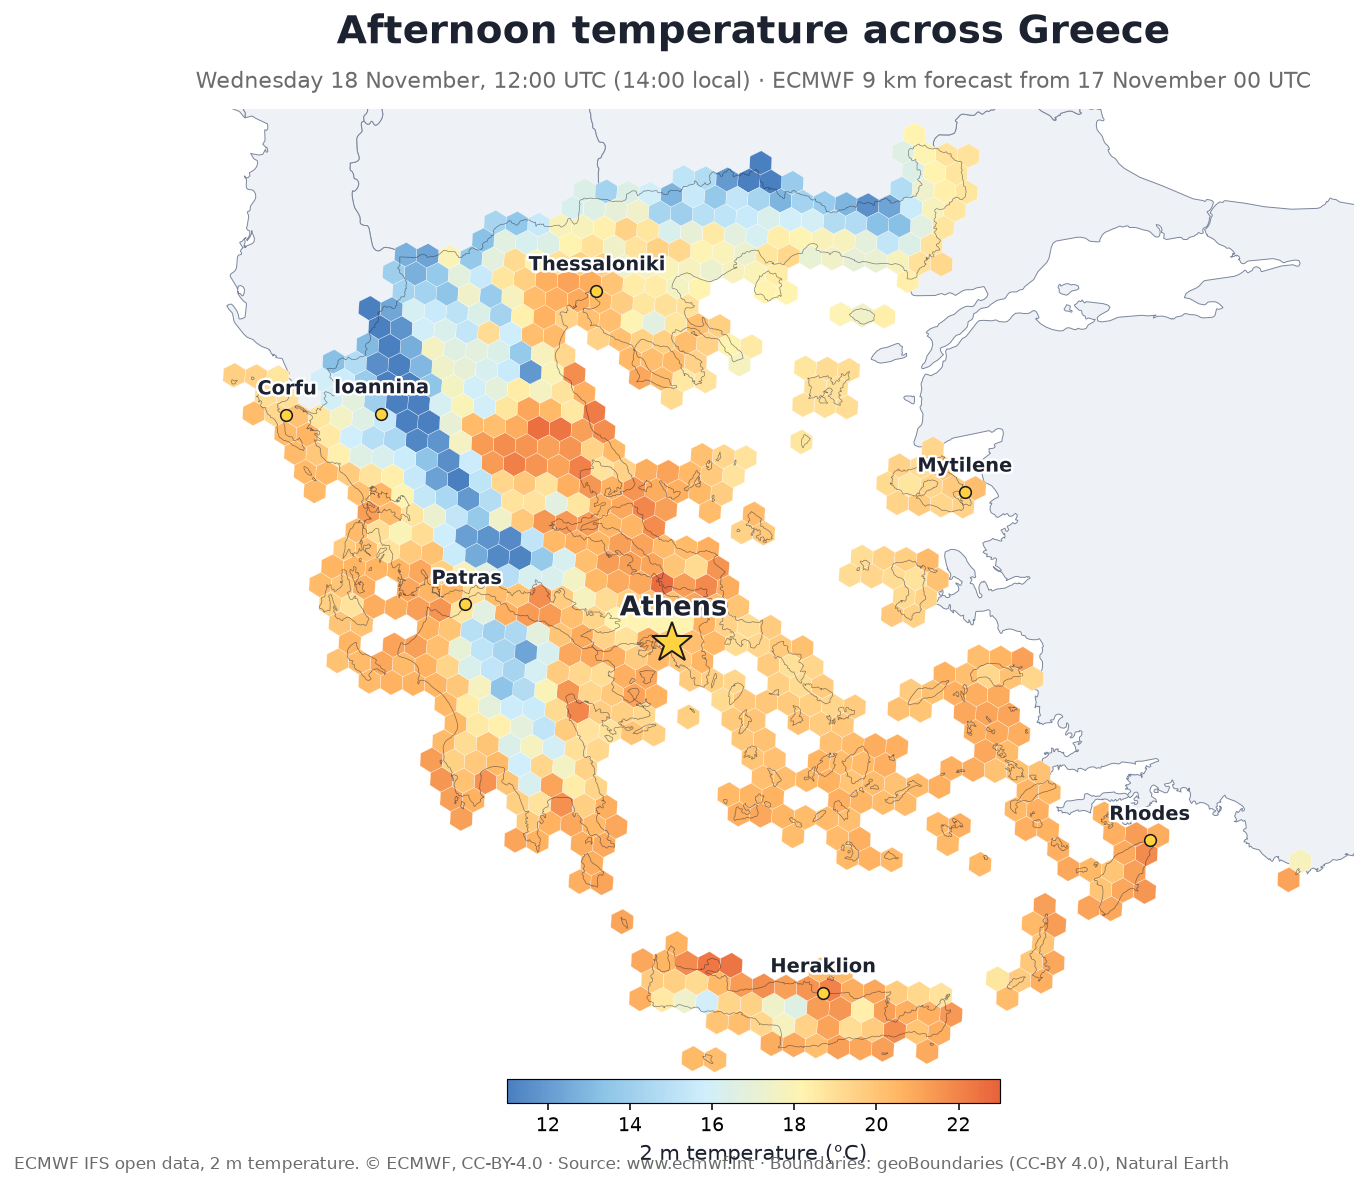

In [6]:
ink, grey, land_bg, coast = "#1d2230", "#6b6b6b", "#eef1f6", "#7a869c"
cmap = LinearSegmentedColormap.from_list("temp", ["#4a7fc0", "#8ec5e8", "#cfeefc", "#fff3b0", "#ffb562", "#e8623a"])
norm = Normalize(np.floor(np.percentile(vals, 2)), np.ceil(np.percentile(vals, 98)))   # one scale for the whole week
proj = ccrs.AlbersEqualArea(central_longitude=(BBOX[0] + BBOX[1]) / 2, central_latitude=(BBOX[2] + BBOX[3]) / 2,
                            standard_parallels=(BBOX[2] + 1.5, BBOX[3] - 1.5))
halo = [pe.withStroke(linewidth=2.5, foreground="white")]

def when(v):
    local = v.astimezone(ZoneInfo(TIMEZONE))
    return f"{v:%A} {v.day} {v:%B}, {v:%H}:00 UTC ({local:%H}:00 local)"

def base(ax):
    ax.set_extent([BBOX[0], BBOX[1], BBOX[2], BBOX[3]], crs=ccrs.PlateCarree())
    ax.spines["geo"].set_visible(False)
    ax.add_geometries(neighbours, crs=ccrs.PlateCarree(), facecolor=land_bg, edgecolor=coast, linewidth=0.5, zorder=1)

def hexes(ax, d, lw=0.15, outline=0.35):
    ax.add_collection(PolyCollection(polys, transform=ccrs.PlateCarree(), facecolors=cmap(norm(vals[d])),
                                     edgecolors="white", linewidths=lw, zorder=3))
    if outline:
        ax.add_geometries([country], crs=ccrs.PlateCarree(), facecolor="none", edgecolor=ink,
                          linewidth=outline, alpha=0.55, zorder=4)

def colourbar(fig, rect, fs=11):
    cb = fig.colorbar(mcm.ScalarMappable(norm=norm, cmap=cmap), cax=fig.add_axes(rect), orientation="horizontal")
    cb.set_label("2 m temperature (°C)", fontsize=fs, color=ink)
    cb.outline.set_linewidth(0.6)

fig = plt.figure(figsize=(11, 8.6), dpi=140)
ax = fig.add_axes([0.02, 0.1, 0.96, 0.8], projection=proj)
base(ax); hexes(ax, DAY)
for name, la, lo in CITIES:
    ax.plot(lo, la, "o", ms=6, color="#ffd23f", mec="#1a1a1a", mew=0.8, transform=ccrs.PlateCarree(), zorder=10)
    ax.text(lo, la + 0.12, name, transform=ccrs.PlateCarree(), ha="center", va="bottom", fontsize=10,
            fontweight="bold", color=ink, path_effects=halo, zorder=11)
name, clat, clon = CAPITAL
ax.plot(clon, clat, marker="*", ms=22, color="#ffd23f", mec="#1a1a1a", mew=1.0, transform=ccrs.PlateCarree(), zorder=12)
ax.text(clon, clat + 0.16, name, transform=ccrs.PlateCarree(), ha="center", va="bottom", fontsize=14,
        fontweight="bold", color=ink, path_effects=halo, zorder=13)
colourbar(fig, [0.34, 0.075, 0.32, 0.02])
fig.text(0.5, 0.955, f"Afternoon temperature across {COUNTRY}", ha="center", fontsize=20, fontweight="bold", color=ink)
fig.text(0.5, 0.918, f"{when(valid[DAY])} · ECMWF 9 km forecast from {run:%d %B} 00 UTC",
         ha="center", color=grey, fontsize=11.5)
fig.text(0.02, 0.02, "ECMWF IFS open data, 2 m temperature. © ECMWF, CC-BY-4.0 · Source: www.ecmwf.int · "
         "Boundaries: geoBoundaries (CC-BY 4.0), Natural Earth", color=grey, fontsize=8.5)
fig.savefig(f"{COUNTRY.lower()}_map.png", bbox_inches="tight", facecolor="white")
plt.show()

## 5 · The week ahead

The same map for all seven afternoons on one colour scale, so the days can be compared.

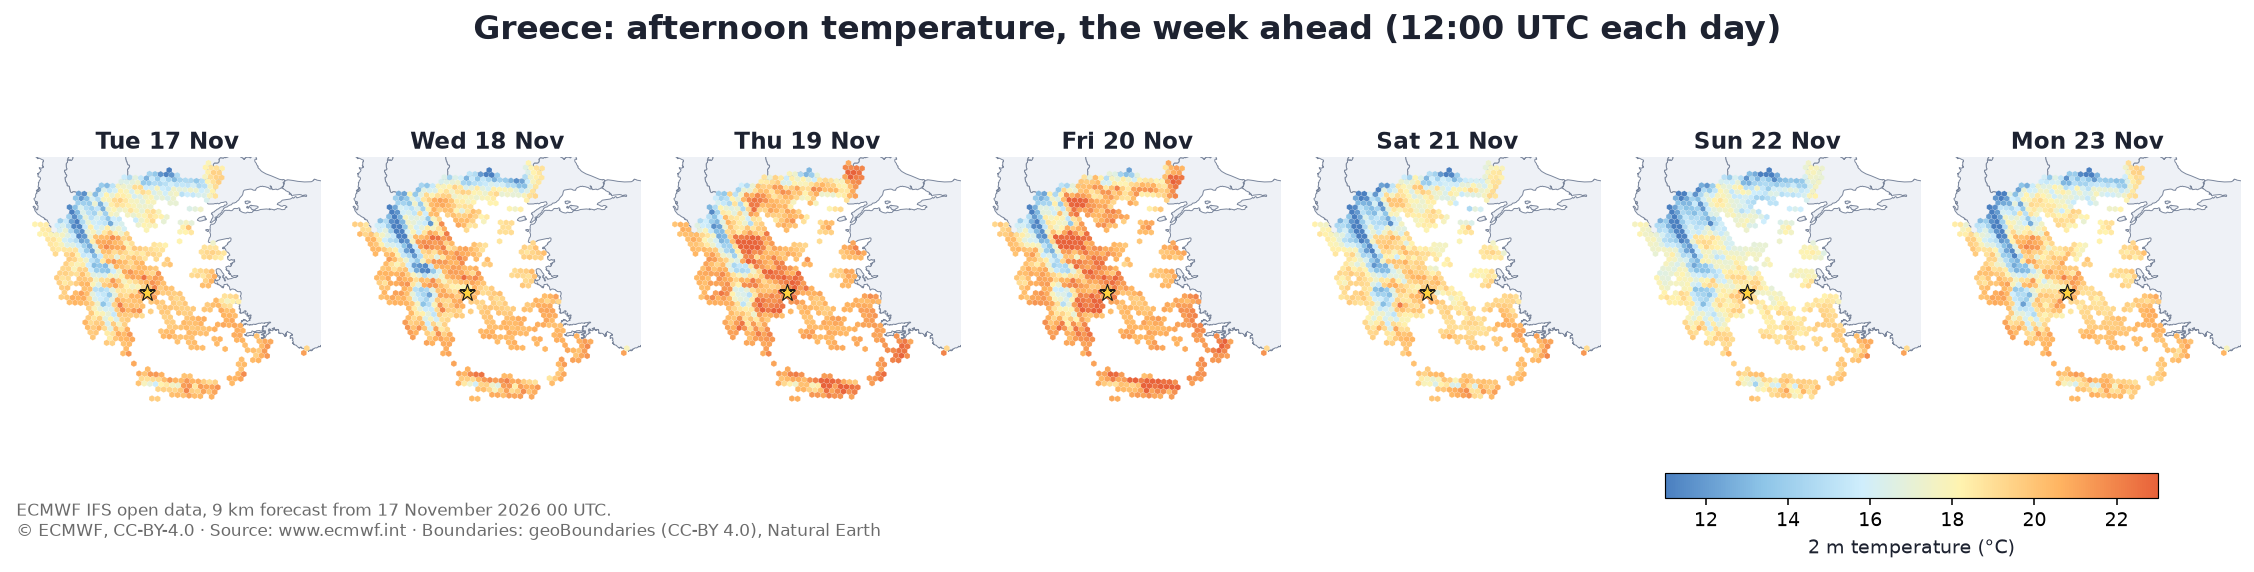

                Tue 17  Wed 18  Thu 19  Fri 20  Sat 21  Sun 22  Mon 23
Athens             21°     19°     23°     22°     22°     20°     20°
Thessaloniki       18°     20°     20°     21°     19°     18°     18°
Ioannina           15°     15°     17°     17°     14°     15°     15°
Patras             19°     20°     20°     19°     18°     17°     19°
Corfu              18°     19°     20°     20°     18°     17°     19°
Mytilene           19°     20°     21°     21°     17°     17°     20°
Rhodes             22°     22°     22°     22°     22°     21°     21°
Heraklion          22°     22°     25°     25°     21°     20°     21°


In [7]:
fig = plt.figure(figsize=(16, 3.9), dpi=140)
w = 1 / 7
for d in range(7):
    ax = fig.add_axes([d * w + 0.003, 0.2, w - 0.006, 0.6], projection=proj)
    base(ax); hexes(ax, d, lw=0.05, outline=0)
    ax.plot(clon, clat, marker="*", ms=9, color="#ffd23f", mec="#1a1a1a", mew=0.6, transform=ccrs.PlateCarree(), zorder=12)
    ax.set_title(f"{valid[d]:%a} {valid[d].day} {valid[d]:%b}", fontsize=12, fontweight="bold", color=ink, pad=4)
colourbar(fig, [0.74, 0.1, 0.22, 0.045], fs=10)
fig.text(0.5, 0.94, f"{COUNTRY}: afternoon temperature, the week ahead ({HOUR:02d}:00 UTC each day)",
         ha="center", fontsize=17, fontweight="bold", color=ink)
fig.text(0.004, 0.03, f"ECMWF IFS open data, 9 km forecast from {run:%d %B %Y} 00 UTC.\n© ECMWF, CC-BY-4.0 · "
         "Source: www.ecmwf.int · Boundaries: geoBoundaries (CC-BY 4.0), Natural Earth", color=grey, fontsize=8.5)
fig.savefig(f"{COUNTRY.lower()}_week.png", bbox_inches="tight", facecolor="white")
plt.show()

print(f"{'':14}" + "".join(f"{v:%a %d}".rjust(8) for v in valid))
for name, la, lo in [CAPITAL] + CITIES:
    j = np.argmin((lat - la) ** 2 + ((lon - lo) * np.cos(np.radians(la))) ** 2)
    print(f"{name:14}" + "".join(f"{t:7.0f}°" for t in temps[:, j]))

## 6 · Your turn 🌍

- **Different day?** Change `DAY` (0 to 6) and re-run from step 4.
- **Night-time instead?** Set `HOUR = 0` or `HOUR = 6` and re-run from step 2.
- **Different country?** Change `COUNTRY`, `ISO3` (`"ITA"`, `"CYP"`, `"HRV"` …), `CAPITAL`, `CITIES`,
  `TIMEZONE` and `BBOX`, then Run all.
- **Different weather?** Try `param="10u"` / `"10v"` for wind, or `"msl"` for pressure, and drop the `- 273.15`.

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`.
Country border from [geoBoundaries](https://www.geoboundaries.org) (CC-BY 4.0; Runfola et al. 2020,
*PLoS ONE* 15(4): e0231866); neighbouring countries from [Natural Earth](https://www.naturalearthdata.com) (public domain).

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) ·
[earthkit](https://earthkit-data.readthedocs.io) · [ecmwf-opendata](https://github.com/ecmwf/ecmwf-opendata)